# PyZX proti Qiskit: primerjava optimizatorjev T-vrat

Eksperiment: na naključnih vezjih primerjamo optimizatorje Qiskit, PyZX in njuni kombinaciji.
Metrike: število T-vrat, skupno število vrat, število dvokubitnih vrat in čas izvajanja.

Struktura zvezka:
1. Uvozi in parametri
2. Pomožne funkcije
3. Izvedba eksperimenta in shranjevanje rezultatov
4. Nalaganje rezultatov in grafi (vsak graf v svoji celici, ponovna izvedba eksperimenta ni potrebna)

## 1. Uvozi

In [1]:
import csv
import json
import os
import platform
import random
import time
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pyzx as zx
import qiskit
from qiskit import QuantumCircuit, qasm2, transpile

from qcGenerator import QuantumCircuitGenerator
from pxOptimizer import PyZXOptimizer
from qiskitOptimizer import CLIFFORD_T_BASIS, QiskitOptimizer
from mixOptimizers import PyZXThenQiskitOptimizer, QiskitThenPyZXOptimizer

## 2. Parametri

In [ ]:
# Seme: vsa naključnost (generator vezij) je določena s tem semenom, zato je eksperiment ponovljiv
seed = 0

# Preiskava po številu kubitov (fiksna globina)
benchmark_qubit_counts = [5, 10, 15, 20, 25]
benchmark_depth = 100

# Preiskava po globini (fiksno število kubitov)
depth_sweep_depths = [25, 50, 100, 150, 200]
depth_sweep_qubits = 10

circuits_per_size = 10
qiskit_level = 3

run_dir = None
results_root = "results"

display_names = {"Original": "Izvirno vezje", "Qiskit only": "Samo Qiskit", "PyZX only": "Samo PyZX",
                 "Qiskit -> PyZX": "Qiskit -> PyZX", "PyZX -> Qiskit": "PyZX -> Qiskit"}

## 3. Eksperiment

In [ ]:
optimizers = {
    "Qiskit only": QiskitOptimizer(optimization_level=qiskit_level),
    "PyZX only": PyZXOptimizer(),
    "Qiskit -> PyZX": QiskitThenPyZXOptimizer(optimization_level=qiskit_level),
    "PyZX -> Qiskit": PyZXThenQiskitOptimizer(),  
}
methods = ["Original"] + list(optimizers)
metrics = ["t_count", "total_gates", "two_qubit_gates", "time_s", "time_per_qubit_s", "time_per_depth_s",
           "t_reduction_pct", "t_reduction_pct_per_qubit", "t_reduction_pct_per_depth"]


def gate_metrics(qc: QuantumCircuit) -> dict:
    ops = transpile(qc, basis_gates=CLIFFORD_T_BASIS, optimization_level=0).count_ops()
    return {
        "total_gates": sum(ops.values()),
        "t_count": ops.get("t", 0) + ops.get("tdg", 0),
        "two_qubit_gates": ops.get("cx", 0),
    }


def file_name(method: str) -> str:
    return method.lower().replace(" -> ", "_then_").replace(" ", "_") + ".qasm"


def ratio_metrics(time_s: float, t_reduction_pct: float, n: int, d: int) -> dict:
    # d je parameter globine generatorja (število plasti vrat)
    return {
        "time_per_qubit_s": time_s / n,
        "time_per_depth_s": time_s / d,
        "t_reduction_pct": t_reduction_pct,
        "t_reduction_pct_per_qubit": t_reduction_pct / n,
        "t_reduction_pct_per_depth": t_reduction_pct / d,
    }


def benchmark_circuit(sweep: str, n: int, d: int, i: int, circuit_seed: int, circuit_dir: str) -> list:
    random.seed(circuit_seed)
    circuit = QuantumCircuitGenerator(num_qubits=n, depth=d).generate()
    os.makedirs(circuit_dir, exist_ok=True)
    qasm2.dump(circuit, os.path.join(circuit_dir, "original.qasm"))
    original = gate_metrics(circuit)
    base = {"sweep": sweep, "qubits": n, "depth": d, "circuit": i, "seed": circuit_seed}
    rows = [{**base, "method": "Original", "time_s": 0.0, **original, **ratio_metrics(0.0, 0.0, n, d)}]

    for name, optimizer in optimizers.items():
        # time_s je samo optimizacija, brez shranjevanja
        start = time.perf_counter()
        optimized = optimizer.optimize(circuit)
        elapsed = time.perf_counter() - start
        qasm2.dump(optimized, os.path.join(circuit_dir, file_name(name)))
        optimized_metrics = gate_metrics(optimized)
        t_reduction_pct = (100 * (original["t_count"] - optimized_metrics["t_count"]) / original["t_count"]
                           if original["t_count"] else 0.0)
        rows.append({**base, "method": name, "time_s": elapsed,
                     **optimized_metrics, **ratio_metrics(elapsed, t_reduction_pct, n, d)})
    return rows

In [4]:
# Ena mapa na število kubitov in na globino, ena podmapa na vezje
run_dir = os.path.join(results_root, datetime.now().strftime("%Y-%m-%d_%H-%M-%S"))
runs = []
benchmark_start = time.perf_counter()

for n in benchmark_qubit_counts:
    for i in range(circuits_per_size):
        runs += benchmark_circuit("qubits", n, benchmark_depth, i, seed + n * 1000 + i,
                                  os.path.join(run_dir, f"qubits_{n}", f"circuit_{i:02d}"))
        print(f"kubiti {n}: vezje {i + 1}/{circuits_per_size} "
              f"({(time.perf_counter() - benchmark_start) / 60:.1f} min)")

for d in depth_sweep_depths:
    for i in range(circuits_per_size):
        runs += benchmark_circuit("depth", depth_sweep_qubits, d, i, seed + 1_000_000 + d * 1000 + i,
                                  os.path.join(run_dir, f"depth_{d}", f"circuit_{i:02d}"))
        print(f"globina {d}: vezje {i + 1}/{circuits_per_size} "
              f"({(time.perf_counter() - benchmark_start) / 60:.1f} min)")

total_runtime_min = (time.perf_counter() - benchmark_start) / 60

kubiti 5: vezje 1/10 (0.1 min)
kubiti 5: vezje 2/10 (0.2 min)
kubiti 5: vezje 3/10 (0.3 min)
kubiti 5: vezje 4/10 (0.4 min)
kubiti 5: vezje 5/10 (0.5 min)
kubiti 5: vezje 6/10 (0.6 min)
kubiti 5: vezje 7/10 (0.8 min)
kubiti 5: vezje 8/10 (0.9 min)
kubiti 5: vezje 9/10 (1.0 min)
kubiti 5: vezje 10/10 (1.2 min)
kubiti 10: vezje 1/10 (1.6 min)
kubiti 10: vezje 2/10 (2.0 min)
kubiti 10: vezje 3/10 (2.6 min)
kubiti 10: vezje 4/10 (3.0 min)
kubiti 10: vezje 5/10 (3.4 min)
kubiti 10: vezje 6/10 (3.8 min)
kubiti 10: vezje 7/10 (4.2 min)
kubiti 10: vezje 8/10 (4.7 min)
kubiti 10: vezje 9/10 (5.1 min)
kubiti 10: vezje 10/10 (5.6 min)
kubiti 15: vezje 1/10 (6.9 min)
kubiti 15: vezje 2/10 (8.1 min)
kubiti 15: vezje 3/10 (9.6 min)
kubiti 15: vezje 4/10 (10.8 min)
kubiti 15: vezje 5/10 (12.2 min)
kubiti 15: vezje 6/10 (13.4 min)
kubiti 15: vezje 7/10 (14.6 min)
kubiti 15: vezje 8/10 (15.7 min)
kubiti 15: vezje 9/10 (16.8 min)
kubiti 15: vezje 10/10 (18.7 min)
kubiti 20: vezje 1/10 (20.6 min)
kubiti 

### Povzetek in shranjevanje rezultatov

In [ ]:
summary = []
for sweep, points in (("qubits", benchmark_qubit_counts), ("depth", depth_sweep_depths)):
    for x in points:
        for method in methods:
            rows = [r for r in runs if r["sweep"] == sweep and r[sweep] == x and r["method"] == method]
            summary.append({"sweep": sweep, "qubits": rows[0]["qubits"], "depth": rows[0]["depth"], "method": method,
                            **{f"mean_{m}": float(np.mean([r[m] for r in rows])) for m in metrics}})

parameters = {
    "seed": seed,
    "qubit_sweep": {"qubit_counts": benchmark_qubit_counts, "depth": benchmark_depth,
                    "seed_formula": "seed + qubits * 1000 + circuit_index"},
    "depth_sweep": {"depths": depth_sweep_depths, "qubits": depth_sweep_qubits,
                    "seed_formula": "seed + 1000000 + depth * 1000 + circuit_index"},
    "circuits_per_size": circuits_per_size,
    "depth_meaning": "generator depth parameter (number of gate layers)",
    "t_reduction_pct_formula": "100 * (original T-count - optimized T-count) / original T-count",
    "qiskit_optimization_level": qiskit_level,
    "pyzx_then_qiskit_optimization_level": optimizers["PyZX -> Qiskit"].qiskit_optimizer.optimization_level,
    "note": "PyZX -> Qiskit uses Qiskit level 1: at level 2/3 Qiskit re-synthesizes PyZX output and inflates the T-count",
    "pyzx_qiskit_conversion_level": 0,
    "count_basis": CLIFFORD_T_BASIS,
    "started": os.path.basename(run_dir),
    "total_runtime_min": total_runtime_min,
    "qiskit_version": qiskit.__version__,
    "pyzx_version": zx.__version__,
    "python_version": platform.python_version(),
}
with open(os.path.join(run_dir, "results.json"), "w") as f:
    json.dump({"parameters": parameters, "summary": summary, "runs": runs}, f, indent=2)
for file, rows in (("summary.csv", summary), ("runs.csv", runs)):
    with open(os.path.join(run_dir, file), "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

print(f"Vezja, results.json, summary.csv in runs.csv shranjeni v {run_dir}")
print("Vezje ponovno naložiš z: QuantumCircuit.from_qasm_file(pot)")

Vezja, results.json, summary.csv in runs.csv shranjeni v results\2026-10-31_10-43-22
Vezje ponovno naložiš z: QuantumCircuit.from_qasm_file(pot)


## 4. Grafi

Celica za nalaganje prebere `results.json` (zadnji zagon ali mapa iz `run_dir`), zato lahko vsak graf
spodaj ponovno izrišeš brez ponovnega zagona eksperimenta.

In [19]:
if run_dir is None:
    run_dir = os.path.join(results_root, sorted(os.listdir(results_root))[-1])
with open(os.path.join(run_dir, "results.json")) as f:
    saved = json.load(f)
summary, parameters = saved["summary"], saved["parameters"]

benchmark_qubit_counts = parameters["qubit_sweep"]["qubit_counts"]
benchmark_depth = parameters["qubit_sweep"]["depth"]
depth_sweep_depths = parameters["depth_sweep"]["depths"]
depth_sweep_qubits = parameters["depth_sweep"]["qubits"]
circuits_per_size = parameters["circuits_per_size"]
qiskit_level = parameters["qiskit_optimization_level"]
print(f"Naloženi rezultati iz {run_dir}")

Naloženi rezultati iz results\2026-10-31_10-43-22


In [ ]:
colors = {"Original": "#898781", "Qiskit only": "#2a78d6", "PyZX only": "#eb6834",
          "Qiskit -> PyZX": "#1baf7a", "PyZX -> Qiskit": "#6250d6"}
markers = {"Original": "o", "Qiskit only": "s", "PyZX only": "^", "Qiskit -> PyZX": "D", "PyZX -> Qiskit": "v"}

optimizer_only = {"mean_time_s", "mean_time_per_qubit_s", "mean_time_per_depth_s",
                  "mean_t_reduction_pct", "mean_t_reduction_pct_per_qubit", "mean_t_reduction_pct_per_depth"}

common_panels = {"mean_t_count": "Povprečno število T-vrat",
                 "mean_total_gates": "Povprečno skupno število vrat (Clifford+T)",
                 "mean_two_qubit_gates": "Povprečno število dvokubitnih vrat (CX)",
                 "mean_t_reduction_pct": "Povprečni delež odstranjenih T-vrat (%)",
                 "mean_time_s": "Povprečni čas izvajanja (s)"}
level_note = f"Qiskit stopnja {qiskit_level} (PyZX -> Qiskit: stopnja 1)"


def plot_sweep(sweep: str, xs: list, xlabel: str, panels: dict, subtitle: str, file: str):
    methods = list(display_names)
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, (key, title) in zip(axes.flat, panels.items()):
        for method in methods:
            if key in optimizer_only and method == "Original":
                continue
            ys = [s[key] for s in summary if s["sweep"] == sweep and s["method"] == method]
            ax.plot(xs, ys, color=colors[method], marker=markers[method], markersize=6, linewidth=2,
                    label=display_names[method])
        ax.set_title(title, loc="left", fontsize=11)
        ax.set_xlabel(xlabel)
        ax.set_xticks(xs)
        ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_ylim(bottom=0)
    for ax in list(axes.flat)[len(panels):]:
        ax.set_visible(False)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(methods), frameon=False)
    fig.suptitle(subtitle, y=0.94, fontsize=10, color="#52514e")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.savefig(os.path.join(run_dir, file), dpi=150)
    plt.show()

### Graf: preiskava po številu kubitov

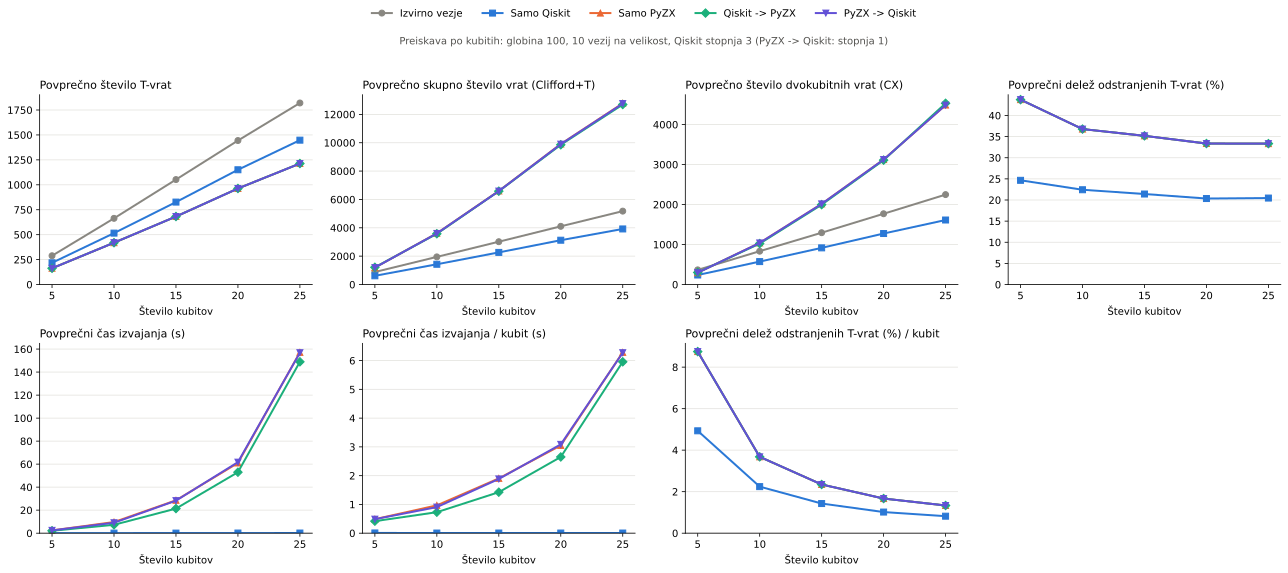

In [21]:
plot_sweep("qubits", benchmark_qubit_counts, "Število kubitov",
           common_panels | {"mean_time_per_qubit_s": "Povprečni čas izvajanja / kubit (s)",
                            "mean_t_reduction_pct_per_qubit": "Povprečni delež odstranjenih T-vrat (%) / kubit"},
           f"Preiskava po kubitih: globina {benchmark_depth}, {circuits_per_size} vezij na velikost, {level_note}",
           "graph_qubits.png")

### Graf: preiskava po globini

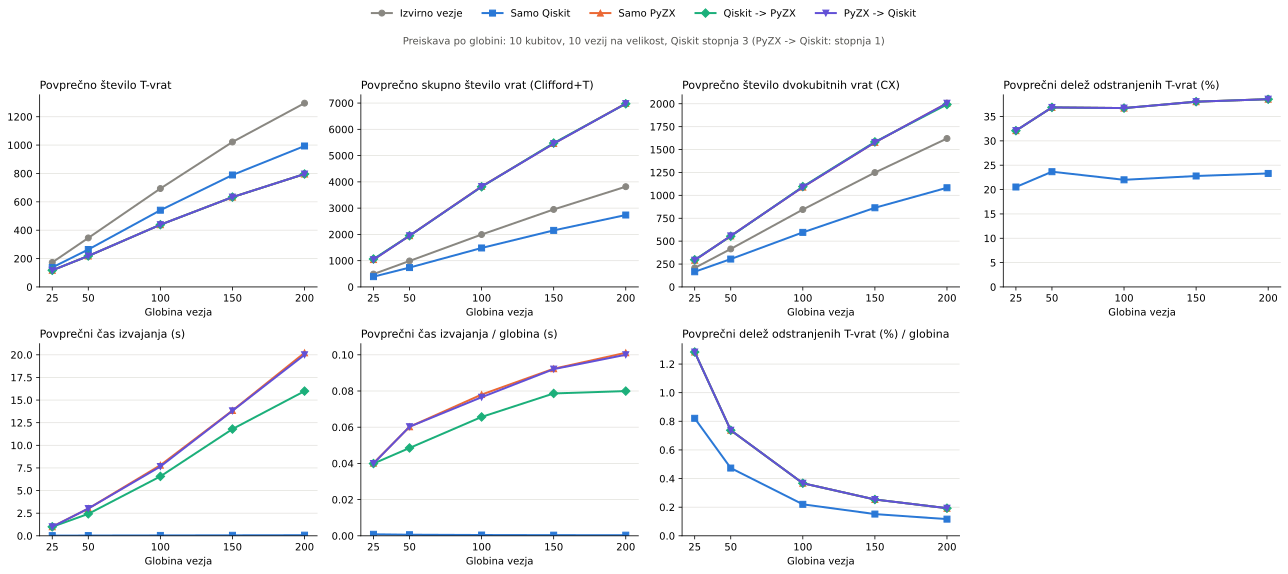

In [32]:
plot_sweep("depth", depth_sweep_depths, "Globina vezja",
           common_panels | {"mean_time_per_depth_s": "Povprečni čas izvajanja / globina (s)",
                            "mean_t_reduction_pct_per_depth": "Povprečni delež odstranjenih T-vrat (%) / globina"},
           f"Preiskava po globini: {depth_sweep_qubits} kubitov, {circuits_per_size} vezij na velikost, {level_note}",
           "graph_depth.png")

### Grafi: T-vrata in čas optimizacije (skupna legenda)

Šest grafov (3 metrike × 2 preiskavi) z isto legendo, razdeljenih v dve sliki:
1. slika: povprečno število T-vrat in povprečno število odstranjenih T-vrat (vrstica = preiskava),
2. slika: povprečni čas optimizacije (s).

Odstranjena T-vrata = povprečno število T-vrat izvirnega vezja − povprečno število T-vrat po optimizaciji.

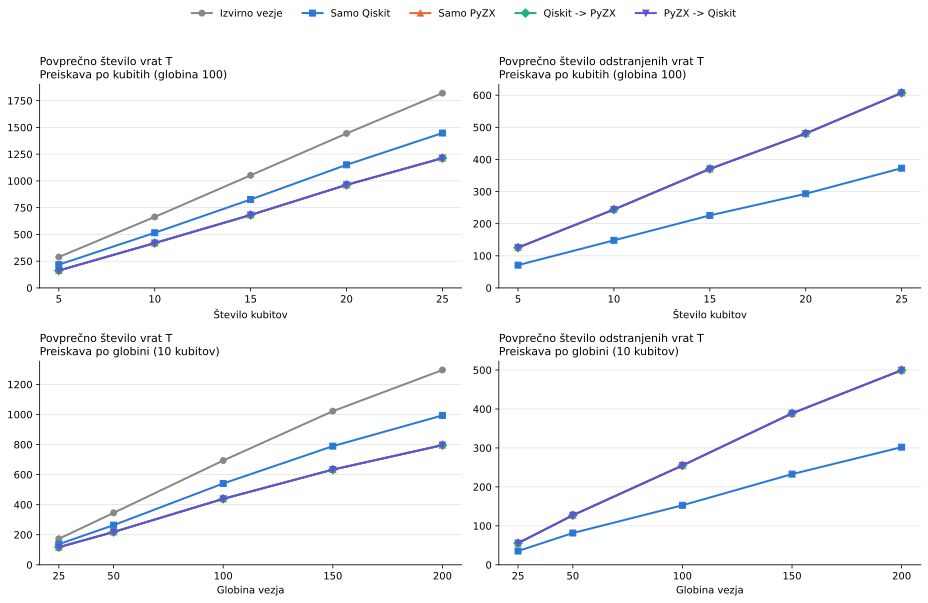

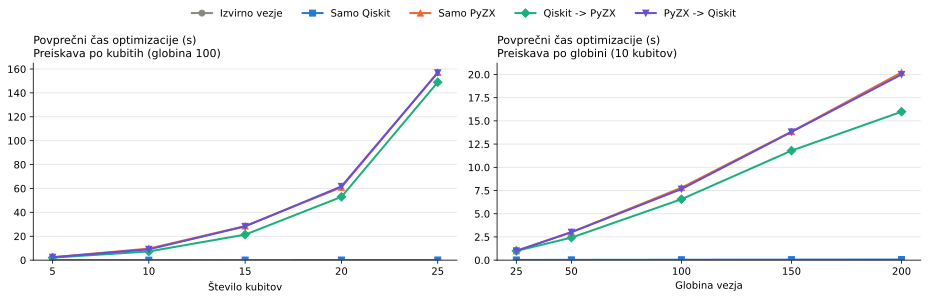

In [ ]:
sweeps = [("qubits", benchmark_qubit_counts, "Število kubitov", f"Preiskava po kubitih (globina {benchmark_depth})"),
          ("depth", depth_sweep_depths, "Globina vezja", f"Preiskava po globini ({depth_sweep_qubits} kubitov)")]


def sweep_values(sweep: str, method: str, key: str) -> list:
    return [s[key] for s in summary if s["sweep"] == sweep and s["method"] == method]


def removed_t_gates(sweep: str, method: str) -> list:
    original = sweep_values(sweep, "Original", "mean_t_count")
    return [o - t for o, t in zip(original, sweep_values(sweep, method, "mean_t_count"))]


def draw_metric(ax, sweep, xs, xlabel, title, values):
    for method in display_names:
        ys = values(sweep, method)
        if ys is None:  # izvirno vezje nima odstranjenih vrat in časa optimizacije
            ax.plot([], [], color=colors[method], marker=markers[method], markersize=6, linewidth=2,
                    label=display_names[method])
            continue
        ax.plot(xs, ys, color=colors[method], marker=markers[method], markersize=6, linewidth=2,
                label=display_names[method])
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_xticks(xs)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(bottom=0)


def plot_columns(columns: list, file: str, horizontal: bool = False):
    n_rows, n_cols = (len(columns), len(sweeps)) if horizontal else (len(sweeps), len(columns))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5 * n_cols, 4.2 * n_rows), squeeze=False)
    
    for s, (sweep, xs, xlabel, sweep_title) in enumerate(sweeps):
        for c, (title, values) in enumerate(columns):
            ax = axes[c, s] if horizontal else axes[s, c]
            draw_metric(ax, sweep, xs, xlabel, f"{title}\n{sweep_title}", values)
            
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    
    fig.savefig(os.path.join(run_dir, file), dpi=150, bbox_inches="tight")
    plt.show()


t_count_column = ("Povprečno število vrat T", lambda sw, m: sweep_values(sw, m, "mean_t_count"))
removed_column = ("Povprečno število odstranjenih vrat T",
                  lambda sw, m: None if m == "Original" else removed_t_gates(sw, m))
time_column = ("Povprečni čas optimizacije (s)",
               lambda sw, m: None if m == "Original" else sweep_values(sw, m, "mean_time_s"))

plot_columns([t_count_column, removed_column], "graph_t_gates.png")
plot_columns([time_column], "graph_time.png", horizontal=True)